In [7]:
import os 
from tqdm import tqdm 
import tensorflow as tf
import keras
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split
import numpy as np

In [8]:
DATA_PATH_TRAINING = ('../data/Training/')

x = []
y = []
counter = 0

classes = os.listdir(DATA_PATH_TRAINING)
print(classes)

['glioma', 'meningioma', 'notumor', 'pituitary']


## Preprocessing

In [9]:
for class_name in os.listdir(DATA_PATH_TRAINING):
    for fileName in tqdm(os.listdir(f"{DATA_PATH_TRAINING}{class_name}")):
        path = f"{DATA_PATH_TRAINING}{class_name}/{fileName}"
        label = counter

        image = tf.keras.preprocessing.image.load_img(path, target_size=(224, 224))
        image = tf.keras.preprocessing.image.img_to_array(image)

        x.append(image)
        y.append(label)

    counter += 1

100%|██████████| 1400/1400 [00:04<00:00, 331.90it/s]


In [10]:
x = np.array(x)
y = np.array(y)

x = x.astype('float32') / 255.0

## Train Test Split

In [11]:
# 80 : 10 : 10

X_train, X_temp, y_train, y_temp = train_test_split(
    x, y, test_size=0.2, random_state=42
)

X_test, X_val, y_test, y_val = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

# Ubah label jadi One Hot Encoder
y_train = keras.utils.to_categorical(y_train)
y_test = keras.utils.to_categorical(y_test)
y_val = keras.utils.to_categorical(y_val)

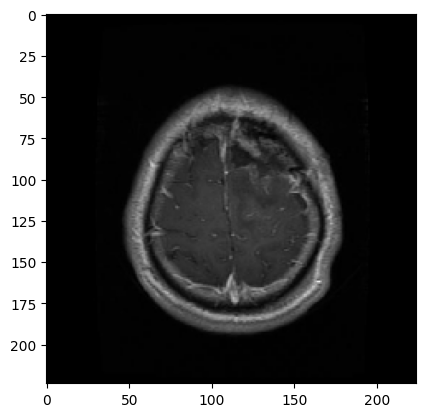

In [12]:
plt.imshow(X_train[0])


## Layer

In [13]:
model = keras.Sequential([
    keras.layers.Conv2D(16, (5,5), activation='relu', input_shape=(224,224, 3)),
    keras.layers.MaxPooling2D(pool_size=(2,2), strides=2),
    keras.layers.Conv2D(32, (5,5), activation='relu'),
    keras.layers.MaxPooling2D(pool_size=(2,2), strides=2),
    keras.layers.Conv2D(64, (5,5), activation='relu'),
    keras.layers.MaxPooling2D(pool_size=(2,2), strides=2),
    keras.layers.Flatten(),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dropout(0.4),
    keras.layers.Dense(4, activation='softmax'),
])

print(model.summary())

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 220, 220, 16)      1216      
                                                                 
 max_pooling2d (MaxPooling2D  (None, 110, 110, 16)     0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 106, 106, 32)      12832     
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 53, 53, 32)       0         
 2D)                                                             
                                                                 
 conv2d_2 (Conv2D)           (None, 49, 49, 64)        51264     
                                                                 
 max_pooling2d_2 (MaxPooling  (None, 24, 24, 64)       0

In [14]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['Accuracy']
)

history = model.fit(
    X_train, y_train, batch_size=120, validation_data=(X_val, y_val), epochs=30
)

Epoch 1/30
38/38 [==============================] - 237s 6s/step - loss: 1.0307 - Accuracy: 0.5471 - val_loss: 0.7415 - val_Accuracy: 0.6893
Epoch 2/30
38/38 [==============================] - 268s 7s/step - loss: 0.7269 - Accuracy: 0.7107 - val_loss: 0.5235 - val_Accuracy: 0.7964
Epoch 3/30
38/38 [==============================] - 286s 8s/step - loss: 0.5813 - Accuracy: 0.7681 - val_loss: 0.4341 - val_Accuracy: 0.8446
Epoch 4/30
38/38 [==============================] - 266s 7s/step - loss: 0.4949 - Accuracy: 0.8051 - val_loss: 0.3809 - val_Accuracy: 0.8714
Epoch 5/30
38/38 [==============================] - 220s 6s/step - loss: 0.4382 - Accuracy: 0.8190 - val_loss: 0.3231 - val_Accuracy: 0.8804
Epoch 6/30
38/38 [==============================] - 226s 6s/step - loss: 0.3623 - Accuracy: 0.8467 - val_loss: 0.2698 - val_Accuracy: 0.9018
Epoch 7/30
38/38 [==============================] - 219s 6s/step - loss: 0.3076 - Accuracy: 0.8676 - val_loss: 0.2416 - val_Accuracy: 0.9161
Epoch 8/30
38

Setelah membandingkan 3 model: 
- model_1 : arsitektur data flatten tapi ada early stopping
- model_2 : arsitektur data flatten tanpa early stopping
- model_3 : arsitektur GlobalAveragePooling tanpa early stopping

Saya menyimpulkan bahwa model paling bagus itu adalah model 2, karena accuracynya 97% dan val accuracynya 95% (tidak berbeda jauh). 
tidak menunjukkan adanya overfitting (nilai accuracy dan val accuracy beda jauh) dan tidak menunjukkan adanya underfitting (accuray dan val accuracy sama sama rendah)

In [15]:
os.makedirs("../models", exist_ok=True)

model.save("../models/brain_tumor_model.keras")

In [16]:
score = model.evaluate(X_test, y_test)
print(f"Test Loss = {score[0]}")
print(f"Test Accuracy : {score[1]}")

18/18 [==============================] - 6s 344ms/step - loss: 0.3705 - Accuracy: 0.9464
Test Loss = 0.3704710304737091
Test Accuracy : 0.9464285969734192


18/18 [==============================] - 7s 340ms/step


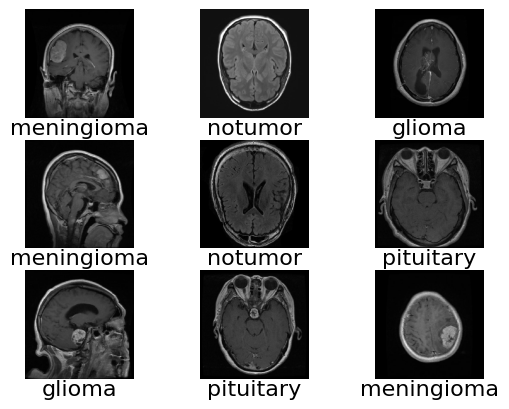

In [17]:
predictions = model.predict(X_test)
predicted_labels = np.argmax(predictions, axis=1)

for i in range(9): 
    plt.subplot(3, 3, i+1)
    plt.imshow(X_test[i], cmap='gray')
    plt.axis('off')
    plt.text(0.5, -0.15, classes[predicted_labels[i]], fontsize=16, ha='center', transform=plt.gca().transAxes)

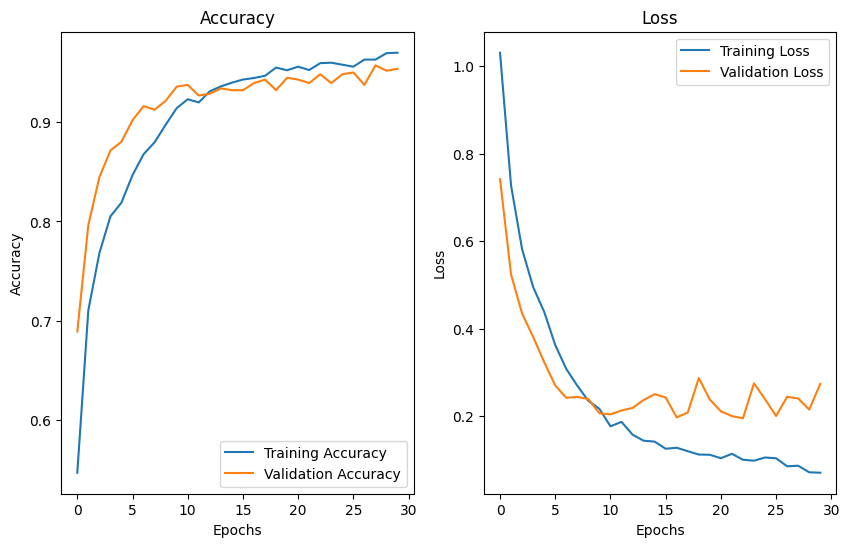

In [18]:
plt.figure(figsize=(10, 6))

# Accuracy Plotting
plt.subplot(1, 2, 1)
plt.plot(history.history['Accuracy'], label='Training Accuracy')
plt.plot(history.history['val_Accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel("Accuracy")
plt.title("Accuracy")
plt.legend()

# Loss Plotting
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel("Loss")
plt.title("Loss")
plt.legend()

plt.show()

In [19]:
DATA_PATH_TESTING = ('../data/Testing/')
X_testing = []
y_testing = []
counter = 0

classes_test = os.listdir(DATA_PATH_TESTING)

In [20]:
for classes_test_name in os.listdir(DATA_PATH_TESTING): 
    for fileName_test in tqdm(os.listdir(f"{DATA_PATH_TESTING}{classes_test_name}")):
        path_test = f"{DATA_PATH_TESTING}{classes_test_name}/{fileName_test}"
        label_test = counter

        image_test = tf.keras.preprocessing.image.load_img(path_test, target_size=(224, 224))
        image_test = tf.keras.preprocessing.image.img_to_array(image_test)

        X_testing.append(image_test)
        y_testing.append(label_test)
        
    counter += 1


100%|██████████| 400/400 [00:00<00:00, 549.23it/s]


In [21]:
X_testing = np.array(X_testing)
y_testing = np.array(y_testing)

X_testing = X_testing.astype('float32') / 255.0

y_testing = keras.utils.to_categorical(y_testing)

In [22]:
score = model.evaluate(X_testing, y_testing)
print(f"Test Loss = {score[0]}")
print(f"Test Accuracy = {score[1]}")

50/50 [==============================] - 18s 355ms/step - loss: 1.4978 - Accuracy: 0.8775
Test Loss = 1.4977627992630005
Test Accuracy = 0.8774999976158142


50/50 [==============================] - 18s 352ms/step


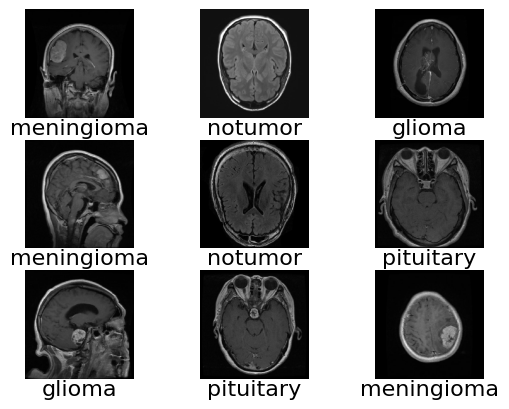

In [23]:
predictions_test = model.predict(X_testing)
predicted_labels_test = np.argmax(predictions_test, axis=1)

for i in range(9): 
    plt.subplot(3, 3, i+1)
    plt.imshow(X_test[i], cmap='gray')
    plt.axis('off')
    plt.text(0.5, -0.15, classes[predicted_labels[i]], fontsize=16, ha='center', transform=plt.gca().transAxes)